# 02 - Benchmark des modèles : pipeline hermétique, validation croisée stratifiée, analyse d'erreurs

**Projet PROJ-CS21 - Détection d'attaques réseau (CIC-IDS2017).** Ce carnet est **exécuté** et ses sorties sont enregistrées.

1. Construire un **pipeline hermétique** : `ColumnTransformer` (sélection des variables + prétraitement) puis le modèle, dans un seul
   `Pipeline` scikit-learn. Aucune statistique d'un pli de validation ne peut atteindre le modèle.
2. Comparer **7 modèles** (plancher, 2 baselines, 4 ensembles dont XGBoost et LightGBM) par **validation croisée stratifiée à 5 plis**.
3. Comparer par paires, puis analyser les erreurs (F1 par classe, matrice de confusion).
4. Faire une **évaluation hold-out** et une **inférence par lot** (CSV en entrée, CSV des prédictions en sortie).
5. Mettre ces résultats en regard des 11 modèles entraînés sur les 2 millions de lignes (scripts 05-07).

In [1]:
import sys, logging, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in (ROOT, ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import settings
from nids.utils.logger import configure_logging
configure_logging(level="WARNING", log_to_file=False, force=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
print("Racine du projet :", ROOT)

Racine du projet : F:\DM_Project


## 1. Le pipeline hermétique

In [2]:
from nids.evaluation import pipeline_benchmark as B
sample = pd.read_parquet(ROOT / "reports/app_data/analysis_sample.parquet")
features = B.feature_columns(sample)
pipe = B.build_model_pipeline("random_forest", features)
print(f"{len(features)} variables d'entrée ; colonnes ignorées par le ColumnTransformer : {[c for c in sample.columns if c not in features]}")
pipe

66 variables d'entrée ; colonnes ignorées par le ColumnTransformer : ['Label', 'source_file']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('flow', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrice

Étapes de `prep` (apprises **dans chaque pli**, sur les lignes d'apprentissage du pli seulement) : infini -> manquant, imputation par
la médiane, log1p signé, suppression des colonnes constantes et corrélées (|r| >= 0,95), standardisation. `cross_validate_models`
**clone et réajuste tout le pipeline** dans chaque pli de `StratifiedKFold`.

**Démonstration de l'étanchéité** : les médianes apprises diffèrent d'un pli à l'autre, la preuve que chaque pli a appris les siennes.

In [3]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
y = sample[settings.LABEL_COLUMN].astype("category").cat.codes.to_numpy()
rows = []
for k, (tr, _) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(sample, y), 1):
    prep = clone(pipe.named_steps["prep"]).fit(sample.iloc[tr])
    inner = prep.named_transformers_["flow"]
    imp = inner.named_steps["imputer"]
    rows.append({"pli": k, "médiane Flow Bytes/s": imp.statistics_[features.index("Flow Bytes/s")],
                 "variables gardées": prep.transform(sample.iloc[:5]).shape[1]})
pd.DataFrame(rows)

,pli,médiane Flow Bytes/s,variables gardées
0,1,142.236970,38
1,2,141.285557,38
2,3,141.024696,38
3,4,141.579301,37
4,5,142.190110,38


## 2. Validation croisée stratifiée (5 plis) de 7 modèles

In [4]:
import time
t0 = time.perf_counter()
res = B.cross_validate_models(sample, n_splits=5, log=print)
print(f"\n{(time.perf_counter() - t0) / 60:.1f} min")
cols = ["display", "family", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "mcc_mean", "detection_rate_mean", "false_alarm_rate_mean", "fit_seconds_mean"]
res.summary[cols].round(4)

Dummy (most frequent)  macro F1 0.0110 +/- 0.0000


Logistic Regression    macro F1 0.8378 +/- 0.0134


Decision Tree          macro F1 0.8987 +/- 0.0088


Random Forest          macro F1 0.9052 +/- 0.0151


Extra Trees            macro F1 0.9032 +/- 0.0224


XGBoost                macro F1 0.9181 +/- 0.0122


LightGBM               macro F1 0.9257 +/- 0.0085

2.4 min


,display,family,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,mcc_mean,detection_rate_mean,false_alarm_rate_mean,fit_seconds_mean
0,LightGBM,ensemble,0.9257,0.0095,0.9202,0.9632,0.9992,0.0090,13.0872
1,XGBoost,ensemble,0.9181,0.0137,0.9091,0.9626,0.9990,0.0085,6.4922
2,Random Forest,ensemble,0.9052,0.0168,0.8938,0.9615,0.9982,0.0120,2.1767
3,Extra Trees,ensemble,0.9032,0.0250,0.8935,0.9593,0.9984,0.0180,1.3218
4,Decision Tree,baseline,0.8987,0.0098,0.8992,0.9561,0.9985,0.0295,0.9890
5,Logistic Regression,baseline,0.8378,0.0150,0.8386,0.9484,0.9982,0.0825,2.6874
6,Dummy (most frequent),floor,0.0110,0.0000,0.0667,0.0000,0.0000,0.0000,0.4429


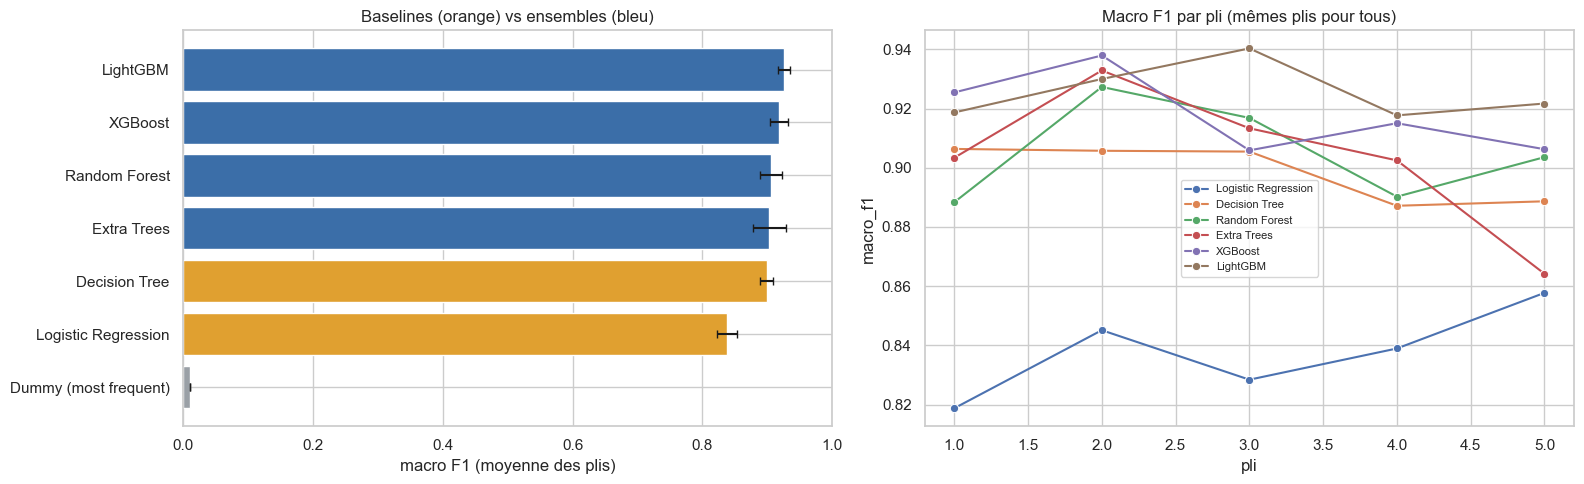

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
s = res.summary.iloc[::-1]
pal = {"floor": "#9aa0a6", "baseline": "#e0a030", "ensemble": "#3b6ea8"}
axes[0].barh(s.display, s.macro_f1_mean, xerr=s.macro_f1_std, color=[pal[f] for f in s.family], capsize=3)
axes[0].set(xlim=(0, 1), xlabel="macro F1 (moyenne des plis)", title="Baselines (orange) vs ensembles (bleu)")
f = res.folds[res.folds.model != "dummy"]
sns.lineplot(f, x="fold", y="macro_f1", hue="display", marker="o", ax=axes[1])
axes[1].set(title="Macro F1 par pli (mêmes plis pour tous)", xlabel="pli"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Comparaison appariée contre la meilleure baseline

In [6]:
best_baseline = res.summary[res.summary.family == "baseline"].iloc[0]["model"]
print("Référence :", B.DISPLAY[best_baseline])
B.paired_comparison(res.folds, best_baseline).round(4)

Référence : Decision Tree


,model,display,mean_diff_vs_decision_tree,std_diff,folds_better,folds
0,lightgbm,LightGBM,0.0270,0.0091,5,5
1,xgboost,XGBoost,0.0194,0.0122,5,5
2,random_forest,Random Forest,0.0066,0.0153,4,5
3,extra_trees,Extra Trees,0.0046,0.0196,3,5
4,decision_tree,Decision Tree,0.0000,0.0000,0,5
5,logistic_regression,Logistic Regression,-0.0609,0.0225,0,5
6,dummy,Dummy (most frequent),-0.8876,0.0098,0,5


In [7]:
from scipy.stats import friedmanchisquare, wilcoxon
wide = res.folds[res.folds.model != "dummy"].pivot(index="fold", columns="display", values="macro_f1")
stat, p = friedmanchisquare(*[wide[c] for c in wide.columns])
print(f"Test de Friedman (H0 : tous les modèles se valent sur les plis) : chi2 = {stat:.2f}, p = {p:.4f}")
best = res.summary.iloc[0]["display"]
print(f"Meilleur modèle : {best}. Avec 5 plis seulement, un test de Wilcoxon apparié ne peut pas descendre sous p = 0,0625 :")
for c in wide.columns:
    if c != best:
        d = wide[best] - wide[c]
        print(f"  {best} - {c:<22} diff moyenne {d.mean():+.4f}  plis gagnés {int((d > 0).sum())}/5")

Test de Friedman (H0 : tous les modèles se valent sur les plis) : chi2 = 18.49, p = 0.0024
Meilleur modèle : LightGBM. Avec 5 plis seulement, un test de Wilcoxon apparié ne peut pas descendre sous p = 0,0625 :
  LightGBM - Decision Tree          diff moyenne +0.0270  plis gagnés 5/5
  LightGBM - Extra Trees            diff moyenne +0.0224  plis gagnés 4/5
  LightGBM - Logistic Regression    diff moyenne +0.0879  plis gagnés 5/5
  LightGBM - Random Forest          diff moyenne +0.0204  plis gagnés 5/5
  LightGBM - XGBoost                diff moyenne +0.0076  plis gagnés 3/5


## 3. Analyse d'erreurs (prédictions hors-pli)

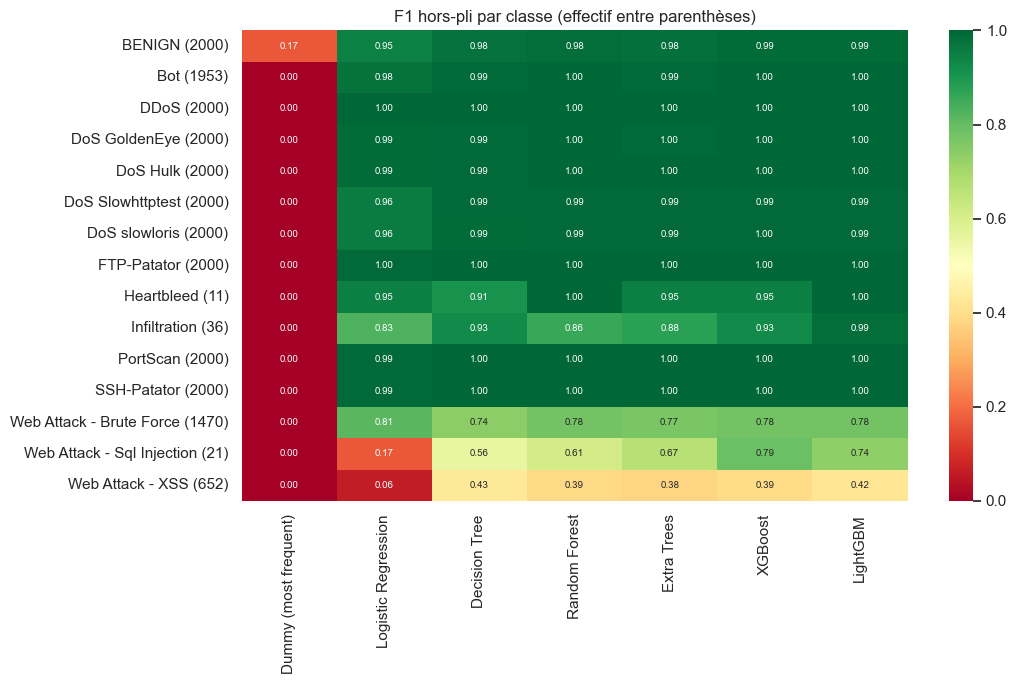

In [8]:
pc = res.per_class_f1()
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(pc.drop(columns="support"), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_yticklabels([f"{c} ({n})" for c, n in zip(pc.index, pc.support)], rotation=0)
ax.set_title("F1 hors-pli par classe (effectif entre parenthèses)"); plt.tight_layout(); plt.show()

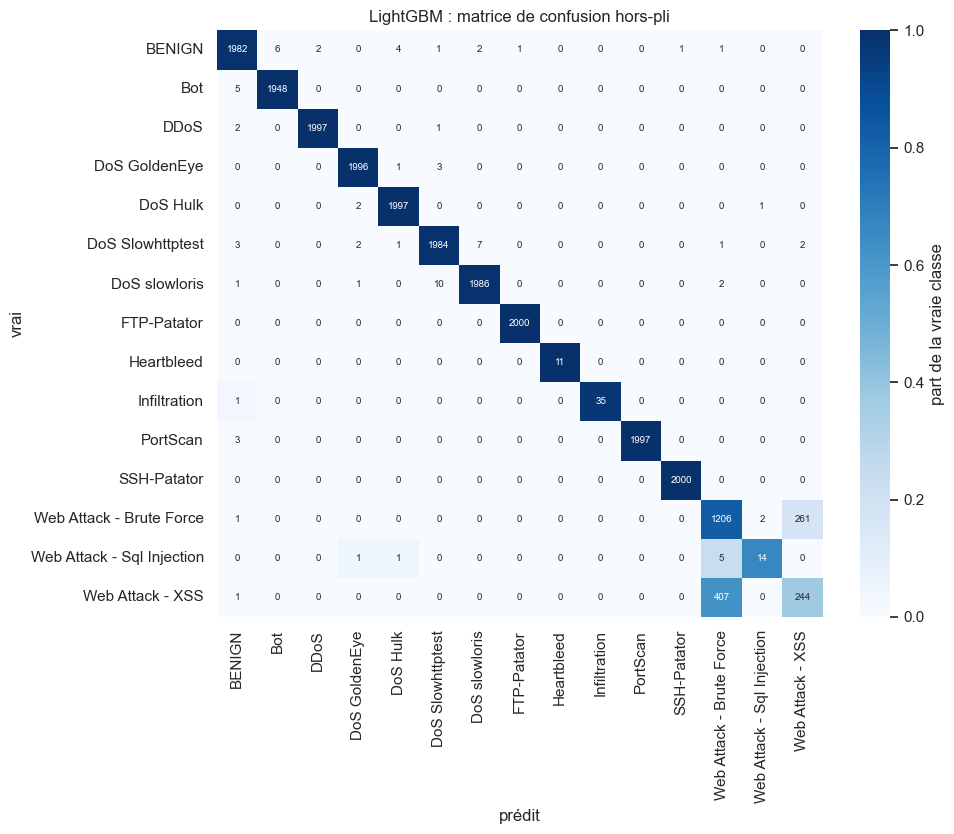

,vrai,prédit,flux,part de la vraie classe
34,Web Attack - XSS,Web Attack - Brute Force,407,0.624
29,Web Attack - Brute Force,Web Attack - XSS,261,0.178
23,DoS slowloris,DoS Slowhttptest,10,0.005
18,DoS Slowhttptest,DoS slowloris,7,0.004
0,BENIGN,Bot,6,0.003
32,Web Attack - Sql Injection,Web Attack - Brute Force,5,0.238
8,Bot,BENIGN,5,0.003
2,BENIGN,DoS Hulk,4,0.002


In [9]:
best_key = res.summary.iloc[0]["model"]
cm = res.confusion(best_key)
norm = cm.div(cm.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(norm, annot=cm, fmt="d", cmap="Blues", ax=ax, annot_kws={"size": 7}, cbar_kws={"label": "part de la vraie classe"})
ax.set(xlabel="prédit", ylabel="vrai", title=f"{B.DISPLAY[best_key]} : matrice de confusion hors-pli"); plt.tight_layout(); plt.show()
conf = [(t, p, int(cm.at[t, p]), cm.at[t, p] / cm.loc[t].sum()) for t in cm.index for p in cm.columns if t != p and cm.at[t, p]]
pd.DataFrame(conf, columns=["vrai", "prédit", "flux", "part de la vraie classe"]).sort_values("flux", ascending=False).head(8).round(3)

**Lecture des erreurs.**

* **Web Attack Brute Force / XSS** forment la confusion dominante, pour tous les modèles : au niveau des statistiques de flux, ces
  attaques sont quasi identiques (même serveur, même port 80, requêtes HTTP de tailles proches). Pour les séparer, il faudrait le contenu
  applicatif, absent de CIC-IDS2017.
* **Bot <-> BENIGN** : une partie du trafic du botnet ressemble à du trafic normal, ce qui donne des attaques manquées.
* **Infiltration, Heartbleed, Sql Injection** ont des dizaines de flux seulement : leur F1 varie beaucoup d'un pli à l'autre.
* La **régression logistique** échoue sur les classes qui demandent des interactions (seuils combinés sur ports et fenêtres TCP) :
  c'est là que les ensembles d'arbres gagnent le plus.

## 4. Hold-out et inférence par lot

Le script 20 a fait la même comparaison sur un échantillon plus grand (3 000 flux par classe), réajusté le meilleur pipeline sur 80 %
et l'a évalué **une seule fois** sur 20 % jamais vus. Le pipeline sauvegardé prend un CSV brut et rend une classe par ligne.

In [10]:
import json, joblib
bench = ROOT / "reports/benchmark"
meta = json.loads((bench / "best_pipeline.json").read_text(encoding="utf-8"))
model = joblib.load(bench / "best_pipeline.joblib")
print("Modèle :", meta["display"], "| entraîné sur", f"{meta['trained_rows']:,}", "lignes")
print("Scores hold-out enregistrés :", {k: round(v, 4) for k, v in meta["holdout_scores"].items()})
pd.read_csv(bench / "cv_summary.csv")[["display", "family", "macro_f1_mean", "macro_f1_std", "fit_seconds_mean"]].round(4)

Modèle : LightGBM | entraîné sur 24,914 lignes
Scores hold-out enregistrés : {'accuracy': 0.9734, 'balanced_accuracy': 0.9317, 'macro_f1': 0.9362, 'weighted_f1': 0.9727, 'mcc': 0.9707, 'detection_rate': 0.9993, 'false_alarm_rate': 0.0083}


,display,family,macro_f1_mean,macro_f1_std,fit_seconds_mean
0,LightGBM,ensemble,0.9170,0.0429,8.2282
1,XGBoost,ensemble,0.9044,0.0443,7.3478
2,Extra Trees,ensemble,0.9009,0.0226,1.3151
3,Random Forest,ensemble,0.8983,0.0246,2.8579
4,Decision Tree,baseline,0.8869,0.0500,0.9415
5,Logistic Regression,baseline,0.8255,0.0132,3.3266
6,Dummy (most frequent),floor,0.0117,0.0000,0.5395


In [11]:
# Inférence par lot : CSV d'entrée -> CSV de prédictions
from sklearn.metrics import classification_report
flows = pd.read_csv(bench / "holdout_flows.csv")
codes = model.predict(flows)                      # le ColumnTransformer ignore la colonne Label
pred = np.array(meta["classes"])[codes]
out = pd.DataFrame({"vrai": flows[settings.LABEL_COLUMN], "prédit": pred, "confiance": model.predict_proba(flows).max(axis=1).round(4)})
out_path = ROOT / "reports/benchmark/notebook_batch_predictions.csv"
out.to_csv(out_path, index=False)
print(f"{len(out):,} flux prédits -> {out_path.relative_to(ROOT)}")
print(classification_report(out["vrai"], out["prédit"], digits=3, zero_division=0))

6,229 flux prédits -> reports\benchmark\notebook_batch_predictions.csv


                            precision    recall  f1-score   support

                    BENIGN      0.993     0.992     0.992       600
                       Bot      0.995     1.000     0.997       391
                      DDoS      1.000     1.000     1.000       600
             DoS GoldenEye      1.000     0.998     0.999       600
                  DoS Hulk      0.997     0.998     0.998       600
          DoS Slowhttptest      0.993     0.993     0.993       600
             DoS slowloris      0.990     0.992     0.991       600
               FTP-Patator      0.998     1.000     0.999       600
                Heartbleed      1.000     1.000     1.000         2
              Infiltration      1.000     0.857     0.923         7
                  PortScan      1.000     0.993     0.997       600
               SSH-Patator      0.997     1.000     0.998       600
  Web Attack - Brute Force      0.737     0.793     0.764       294
Web Attack - Sql Injection      1.000     1.000

## 5. Mise en regard avec les 11 modèles entraînés sur 2 millions de lignes

In [12]:
comp = pd.read_csv(ROOT / "reports/evaluation/model_comparison_tuned.csv")
show = comp[["model", "final_set_uses", "baseline_macro_f1", "tuned_macro_f1", "tuned_detection_rate", "tuned_false_alarm_rate"]].sort_values("tuned_macro_f1", ascending=False)
ens = pd.read_csv(ROOT / "reports/experiments/ensembles/ensembles_comparison.csv")
display(show.round(4))
display(ens[["combiner", "oof_macro_f1", "test_macro_f1", "test_detection_rate", "test_false_alarm_rate"]].round(4))

,model,final_set_uses,baseline_macro_f1,tuned_macro_f1,tuned_detection_rate,tuned_false_alarm_rate
10,XGBoost,baseline,0.9120,0.9183,0.9986,0.0007
2,Random Forest,baseline,0.9150,0.9158,0.9963,0.0007
1,Decision Tree,tuned,0.9141,0.8979,0.9962,0.0008
8,AdaBoost,tuned,0.1673,0.7908,0.9747,0.0005
6,Logistic Regression,baseline,0.6609,0.7138,0.9904,0.0014
4,SVC (RBF kernel),tuned,0.6471,0.7078,0.9995,0.0240
0,KNN,tuned,0.6772,0.6831,0.9997,0.0101
7,SGD Classifier,tuned,0.4864,0.6523,0.9771,0.0029
9,Gradient Boosting,tuned,0.7039,0.6101,0.9996,0.0578
3,Gaussian Naive Bayes,baseline,0.4790,0.4790,0.9985,0.6445


,combiner,oof_macro_f1,test_macro_f1,test_detection_rate,test_false_alarm_rate
0,Single model: Random Forest,0.8497,0.9150,0.9958,0.0007
1,"Equal vote, top 3 by OOF F1 (XGBoost, Random F...",0.8627,0.9149,0.9966,0.0007
2,"Weighted vote, OOF macro F1^4",0.8590,0.9134,0.9983,0.0007
3,Single model: XGBoost,0.8711,0.9120,0.9988,0.0007
4,"Weighted vote, OOF macro F1^1",0.8642,0.9113,0.9986,0.0008
5,"Equal vote, 11 models (baseline set)",0.8528,0.9095,0.9982,0.0009
6,"Equal vote, top 5 by OOF F1 (XGBoost, Random F...",0.8519,0.9076,0.9983,0.0007
7,"Stacking, XGBoost",NaN,0.8941,0.9988,0.0007
8,"Stacking, logistic regression",NaN,0.8847,0.9986,0.0007
9,"Weighted vote, per-class OOF F1",0.7725,0.7724,0.9955,0.0007


## Conclusions

* Le **pipeline hermétique** (`ColumnTransformer` + modèle dans un seul `Pipeline`) supprime toute fuite : imputation, filtre de corrélation
  et standardisation sont réappris dans chaque pli.
* Les **ensembles** (Random Forest, Extra Trees, XGBoost, LightGBM) dominent nettement les **baselines** (régression logistique, arbre seul)
  en macro F1, sur tous les plis. Le plancher (`Dummy`) rappelle que l'accuracy seule ne veut rien dire ici.
* Les erreurs restantes sont concentrées sur Web Attack Brute Force / XSS (indiscernables au niveau flux), sur Bot et sur les trois classes
  minuscules. Ce sont des limites des **données** plus que des modèles.
* Sur les données complètes (scripts 05-07), le même classement se retrouve : XGBoost 0,918 et Random Forest 0,916 de macro F1 sur 504 473
  flux de test, loin devant les modèles linéaires et bayésiens.